# **Explainable Credit Risk Assessment**

##1. Load the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


#**2.Exploratory Data Analysis (EDA)**



*   Here we will look at the data before touching it
*   We want to understand it first, then work on it.



## Basic info about the data


*   check how many rows and columns we have.
*   Check the data type of each column



In [3]:
df.shape
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB
None


##Missing values


*   Find out which columns have empty or missing values.
*   This tells us where we may need to fix things later.



In [4]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,895
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,3116
loan_status,0
loan_percent_income,0


##Traget balance


*   Check how many people defaulted vs how many repaid.
*   This tells us if our data is balanced or imbalanced.



In [5]:
df.head()
df['loan_status'].unique()

df['loan_status'].value_counts()

,count
loan_status,
0,25473
1,7108


<Axes: xlabel='loan_status', ylabel='count'>

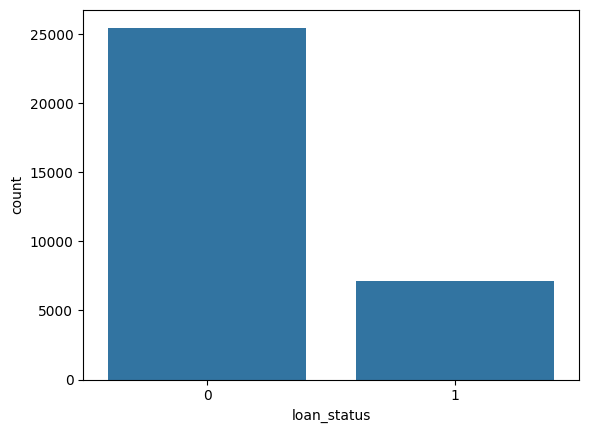

In [6]:
sns.countplot(x='loan_status', data=df)

## Outlier check


*   Look fro values that seem impossible, lke age 144.
*   These are signs of bad data entries.



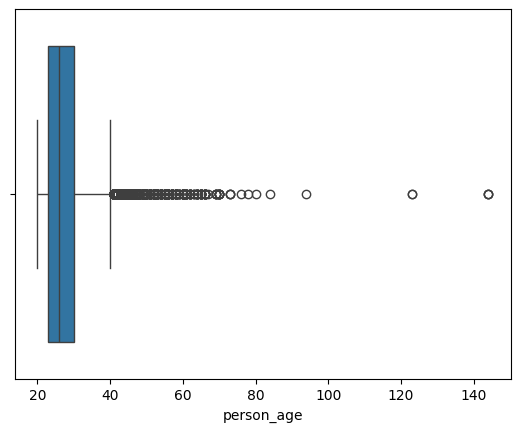

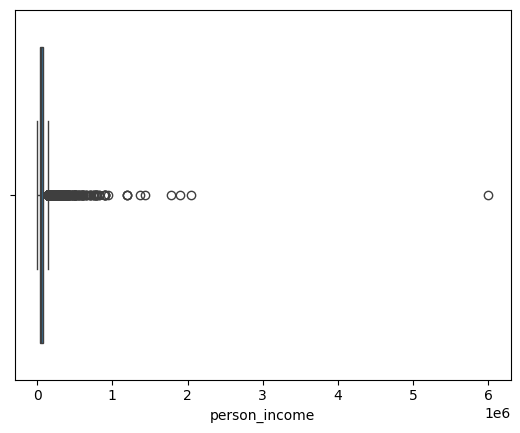

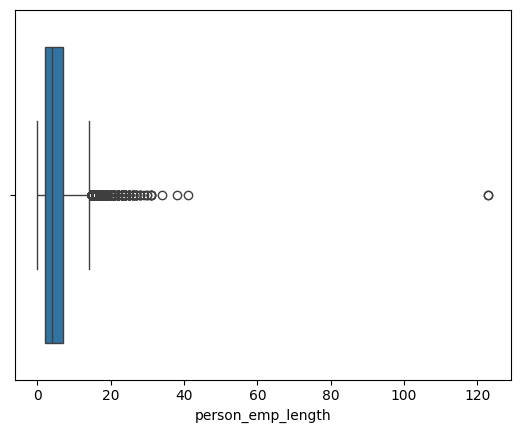

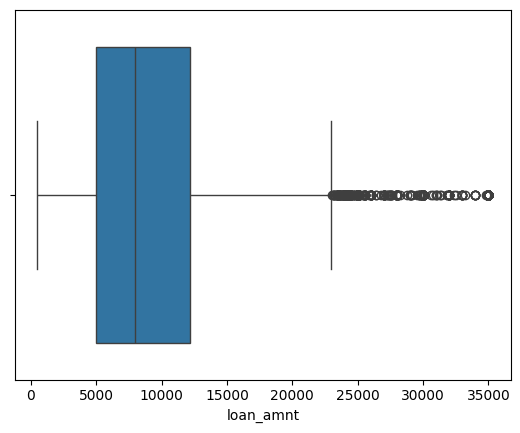

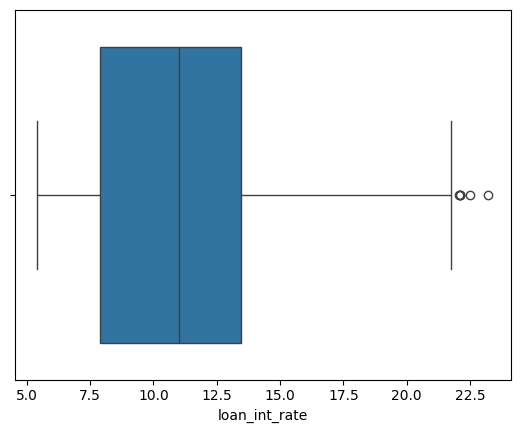

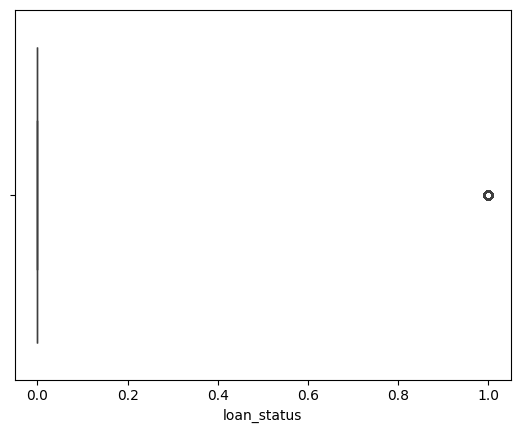

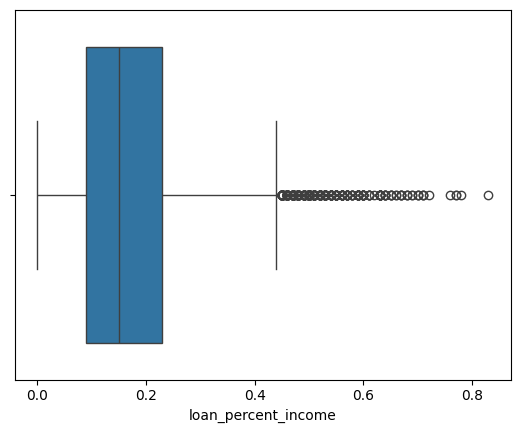

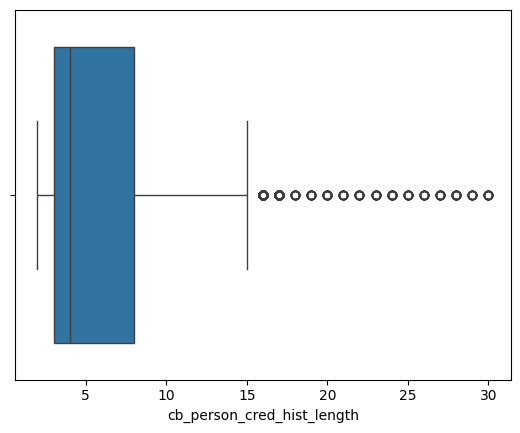

In [7]:
numerical_cols = df.select_dtypes(include=np.number).columns

for i in numerical_cols:
  sns.boxplot(x=df[i])
  plt.show()


In [8]:
(df['person_age'] > 100).sum()

np.int64(5)

In [9]:
(df['person_emp_length'] > 60).sum()

np.int64(2)

In [10]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


##Correlation check


*   See how strongly features are related to each other.
*   This helps us spot repeated or linked information



<Axes: >

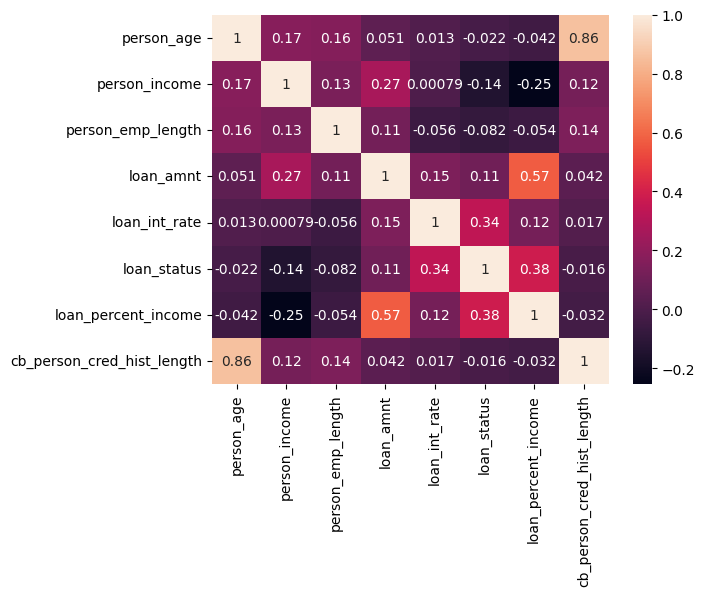

In [11]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

<Axes: xlabel='person_income', ylabel='loan_status'>

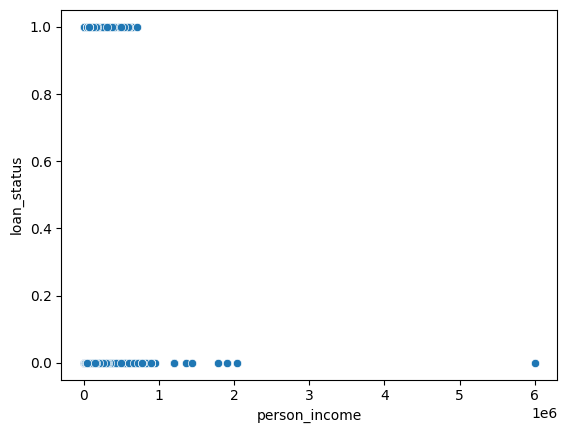

In [12]:
sns.scatterplot(x="person_income", y="loan_status", data=df)

#**3. Data Validation & Outlier Handling**

*   Here we clean the data properly.
*   We remove duplicate rows.

*   We remove rows with an impossible age or work experience.
*   We remove rows with zero or negative income and loan amount.

*   We checck if the interest rate looks realistic.
*   We also flag rows where numbers don't add up correctly.







In [13]:
df_copy = df.copy()

print(f"Original Rows: {df_copy.shape[0]}")
#Remove Duplicate rows
df_copy.drop_duplicates(inplace=True)
print(f"Rows after removing duplicates : {df_copy.shape[0]}")

#Remove ages below 18 or above 100
df_copy = df_copy[df_copy['person_age']>=18]
df_copy = df_copy[df_copy['person_age']<=100]

#Remove employment length greater than age or extreme outliers (>60)
df_copy = df_copy[df_copy['person_emp_length'] <= df_copy['person_age']]
df_copy = df_copy[df_copy['person_emp_length'] <= 60]

#remove the rows with zero or negative income and loan amount
df_copy = df_copy[df_copy['loan_amnt'] > 0]

# Check if the intrest  rate look realistic
print("Loan intrest range from (main: 5.42 and max: 23.22)")

Original Rows: 32581
Rows after removing duplicates : 32416
Loan intrest range from (main: 5.42 and max: 23.22)


In [14]:
df_copy.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,31522.000000,3.152200e+04,31522.000000,31522.000000,28495.000000,31522.000000,31522.000000,31522.000000
mean,27.742529,6.650168e+04,4.782850,9663.771334,11.045220,0.215944,0.169658,5.816097
std,6.218713,5.275216e+04,4.037343,6334.787700,3.230786,0.411482,0.106296,4.063622
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.943800e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.600000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,8.000000e+04,7.000000,12500.000000,13.480000,0.000000,0.230000,8.000000
max,94.000000,2.039784e+06,41.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


# **4.Features, Traget & Train-Test Split**


*   We separate the data into input features and the target.
*   The target is whether the applicant defaulted or not.

*   We split the data into a training part and a testing part.
*   The model learns from the training part only.





In [15]:
X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
numerical_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership','loan_intent','loan_grade','cb_person_default_on_file']

# **5. Handle Class Imbalance**

*   Very few people actually default in this data.
*   If we ignore this, the model may just favor the majority class.

*   We give more importance to the minority class during training.
*   This helps the model actually learn to spot defaulters.





In [18]:
#0 -> no loan (most)
#1 -> yes loan
#weights= 19746/5471
neg, pos = np.bincount(y_train)
scale_weights = neg/pos

In [19]:
scale_weights

np.float64(3.6092122098336685)

In [20]:
y_train.value_counts()

,count
loan_status,
0,19746
1,5471


# **6. Data Preprocessing -- Pipelines & Column Transformer**

*   Raw data is not ready for model directly.
*   We need to prepare numeric and text columns differently.

*   We will build a Pipeline for each model.
*   We will use ColumnTransformer to apply different steps to differentt columns.





## Preprocessing for Logistic Regression

*   Fill missing numeric values.
*   Scale numeric values, since this model is sensitive to scale.

*   Convert category columns into numbers using one-hot-encoding.





In [21]:
#Logitsic Regression : impute + SCALE Numeric, impute + One-Hot-Encoding
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor_lr = ColumnTransformer(
    transformers=[
        #Pipeline - fro numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),

        #Pipeline - for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

## Preprocessing for XGBoost

*   Fill missing numeric values.
*   No scaling eeded here, since tree models don't need it.

*   Convert category columns into numbers using one-hot-encoding.





In [22]:
 #XGBoost: Impute numeric only (No Scaling), impute + One - Hot Encoding

preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - fro numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),

        #Pipeline - for Categorical cols
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical_cols)
    ]
)

# **7.Evaluation Helper Function**

*   We build one common function to check any model's performance.
*   It will show accuracy,precision,recall,F1 score, and more.

*   It will also show a confusion matrix and a precision-recall curve.






In [23]:
#We have to evaluate Logistic Model and XGBoost model on the basis of there metrics
from sklearn.metrics import classification_report, accuracy_score, recall_score, precision_score, f1_score, confusion_matrix, precision_recall_curve
def evaluate_model(model_name, model, X_test, y_test, threshold=None):
  y_pred_prob = model.predict_proba(X_test)[:,1]

  if threshold:
    y_pred = (y_pred_prob > threshold).astype(int)
  else:
    y_pred = model.predict(X_test)


  #Metrices
  accuracy = accuracy_score(y_test, y_pred) #Overall Model's Performance
  precision_s = precision_score(y_test, y_pred) #Of the ones I picked, how many were actually wrong
  recall_s = recall_score(y_test, y_pred) #Out of everything that was really there, how much did you manage to find?
  f1 = f1_score(y_test, y_pred) #Harmonic mean of precision and recall


  #Confusion Matrix
  cm = confusion_matrix(y_test, y_pred)
  class_report = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  print(f"Best Threshold: {best_thresholds}")
  print(f"Accuracy: {accuracy:.2f}")
  print(f"Precision: {precision_s:.2f}")
  print(f"Recall: {recall_s:.2f}")
  print(f"F1 Score: {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)

  #Plotting Confusion Matrix
  sns.heatmap(cm, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.xlabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()

  #Plotting ROC-AUC curve
  precision, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precision)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

# **8. Stratified Cross-Validation**

*   One single train-test split may not be relible.
*   We split the training data into five folds instead.

*   Each fold keeps the same default vs repaid ratio.
*   We check the model's score across all folds.





In [24]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}


In [25]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(max_iter=1000,class_weight='balanced', random_state=42))
])
lr_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [26]:
#XGboost Model
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimator=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weights,random_state=42
    ))
])
xgb_cv_pipeline

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_valu...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimator=300, n_estimators=None, n_jobs=None, ...))])

In [27]:
for cv_name, pipe in [('Logistic Regression', lr_cv_pipeline),
                      ('XGBoost', xgb_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
                      print(cv_name)
                      print(f"ROC-AUC: {cv_results['test_roc_auc'].mean()}")
                      print(f"Accuracy: {cv_results['test_accuracy'].mean()}")
                      print(f"Precision: {cv_results['test_precision'].mean()}")
                      print(f"Recall: {cv_results['test_recall'].mean()}")
                      print(f"F1: {cv_results['test_f1'].mean()}")
                      print()

Logistic Regression
ROC-AUC: 0.8737232512074119
Accuracy: 0.814530375802201
Precision: 0.5513218395513471
Recall: 0.7795687561042799
F1: 0.645855475462873

XGBoost
ROC-AUC: 0.9407667468408704
Accuracy: 0.9103779659873542
Precision: 0.7953353513434215
Recall: 0.7901700433247352
F1: 0.7927258390037191



##

# **9. Baseline Model --Logistic Regression**


*   We stat with a simple model first.
*   This becomes our benchmark to beat.


*  We train it and check its score on the test data.






In [28]:
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight='balanced'))
])
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['person_home_ownership',
                                                   'loan_intent', 'loan_grade',
                                                   'cb_person_default_on_file'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

Baseline Logistic Model Metrics:
Best Threshold: 0.9996228218078613
Accuracy: 0.81
Precision: 0.54
Recall: 0.77
F1 Score: 0.63

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4969
           1       0.54      0.77      0.63      1336

    accuracy                           0.81      6305
   macro avg       0.73      0.79      0.75      6305
weighted avg       0.85      0.81      0.82      6305



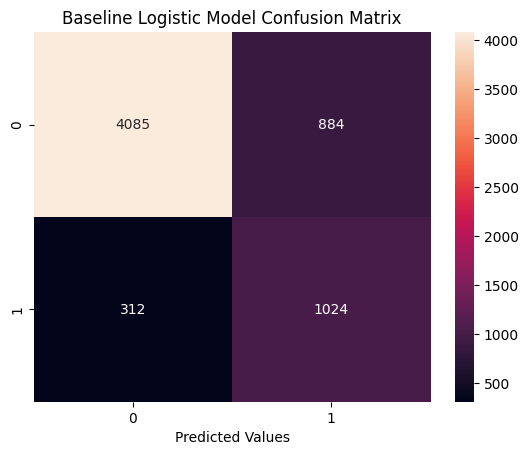

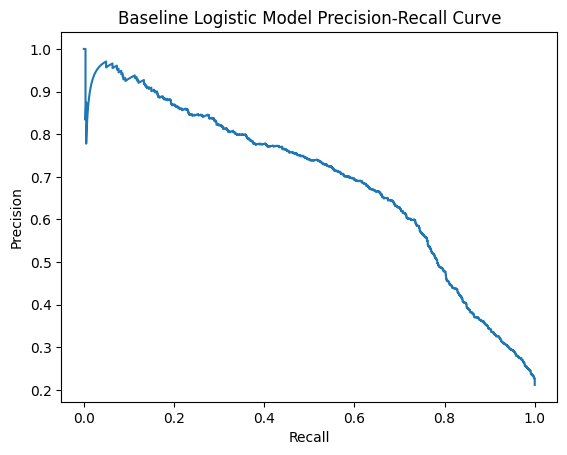

In [46]:
#Evaluate the Logistic Model.
evaluate_model("Baseline Logistic Model", baseline_model, X_test, y_test)

#**10. XGBoost Hyperparameter Tuning**

*   Now we move to a strongger model, XGBoost.
*   Amodel has many settings called hyperparameters.

*   We search for the best combination of these settings.
*   We use cross-validation  while searching, so th result is reliable





In [30]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weights,random_state=42))
])
xg_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['person_age',
                                                   'person_income',
                                                   'person_emp_length',
                                                   'loan_amnt', 'loan_int_rate',
                                                   'loan_percent_income',
                                                   'cb_person_cred_hist_length']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_valu...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

In [31]:
from scipy.stats import uniform, randint

In [32]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier_learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample" : uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" : uniform(0.6,0.4), #Columns sampling
    "classifier__min_child_weight" : randint(1, 10),
    "classifier__gamma" : uniform(0, 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits -> simpler tree -> low overfitting

In [33]:
# Redefining the correct param_grid with the double underscore fix
param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample" : uniform(0.6,0.4),
    "classifier__colsample_bytree" : uniform(0.6,0.4),
    "classifier__min_child_weight" : randint(1, 10),
    "classifier__gamma" : uniform(0, 5)
}

random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['person_age',
                                                                                'person_income',
                                                                                'person_emp_length',
                                                                                'loan_amnt',
                                                                                'loan_int_rate',
                                                                                'loan_percent_income'...
                                        'classifier__min_child_weight': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79350cd6c170>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x79350cd9eea0>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x79350cf78830>},
                   scoring='average_precision', verbose=1)

In [34]:
print(f"Score after performing tunning {random_search.best_score_:.2f}")

Score after performing tunning 0.91


In [35]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.9374528626462779),
 'classifier__gamma': np.float64(0.8331123064833307),
 'classifier__learning_rate': np.float64(0.09882547753898406),
 'classifier__max_depth': 5,
 'classifier__min_child_weight': 4,
 'classifier__n_estimators': 349,
 'classifier__subsample': np.float64(0.9279436634187999)}

# **11.Compare Both Models Side by Side**

*   We now compare Logistic Regression adn XGBoost.
*   We look at there scores together in one table.

*   This helps us pick the better performing model.





Logistic Regression Metrics:
Best Threshold: 0.9996228218078613
Accuracy: 0.81
Precision: 0.54
Recall: 0.77
F1 Score: 0.63

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.82      0.87      4969
           1       0.54      0.77      0.63      1336

    accuracy                           0.81      6305
   macro avg       0.73      0.79      0.75      6305
weighted avg       0.85      0.81      0.82      6305



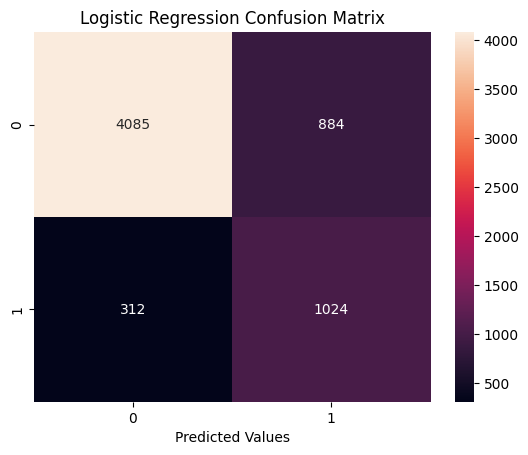

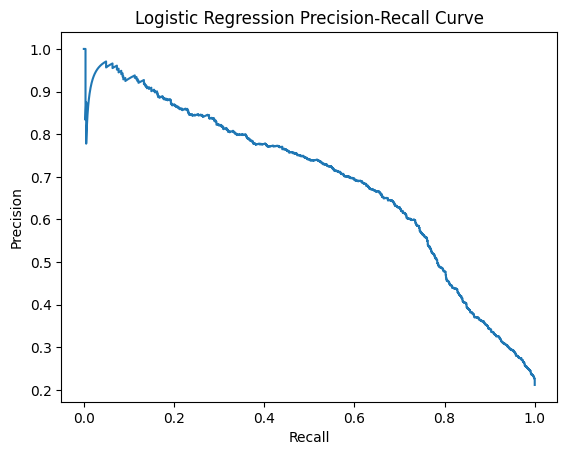

In [47]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

XGBoost Metrics:
Best Threshold: 0.9996228218078613
Accuracy: 0.92
Precision: 0.82
Recall: 0.79
F1 Score: 0.80

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.95      0.95      4969
           1       0.82      0.79      0.80      1336

    accuracy                           0.92      6305
   macro avg       0.88      0.87      0.87      6305
weighted avg       0.92      0.92      0.92      6305



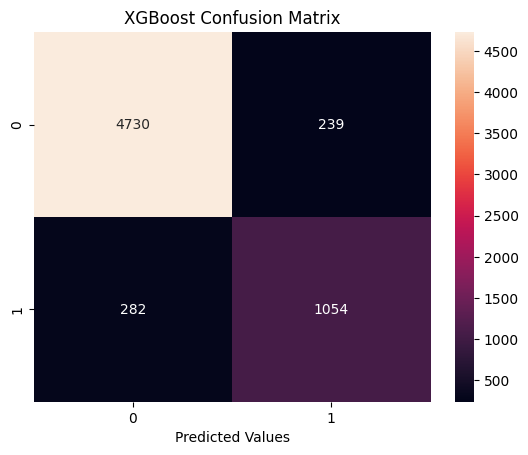

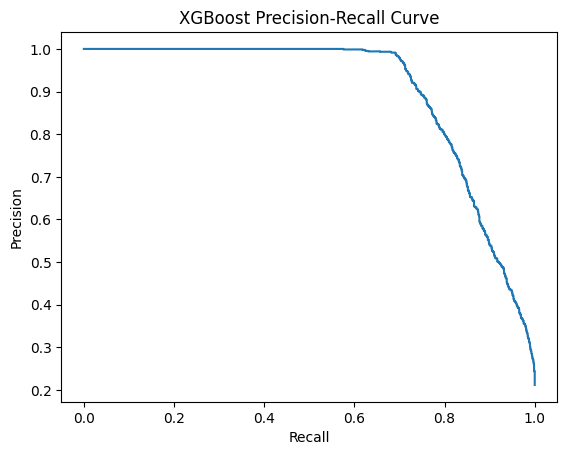

In [48]:
#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, X_test, y_test)

# **12.Optimizing the Classification Threshold**

*   The model gives a probability, not a direct yes or no.
*   We decide a cut-off to turn it into a decision.

*   We check different cut-off ppoints and pick the best one.




XGBoost Metrics:
Best Threshold: 0.9996228218078613
Accuracy: 0.79
Precision: 0.00
Recall: 0.00
F1 Score: 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      4969
           1       0.00      0.00      0.00      1336

    accuracy                           0.79      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.62      0.79      0.69      6305



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

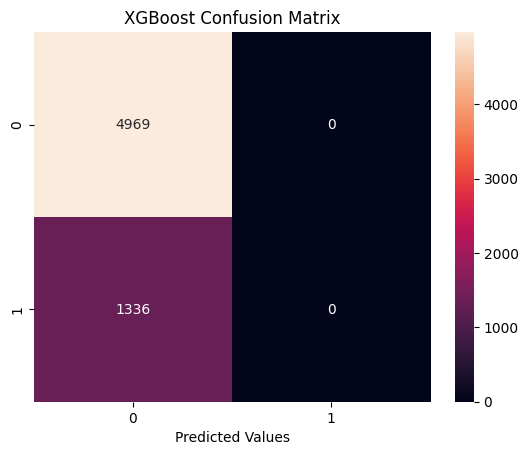

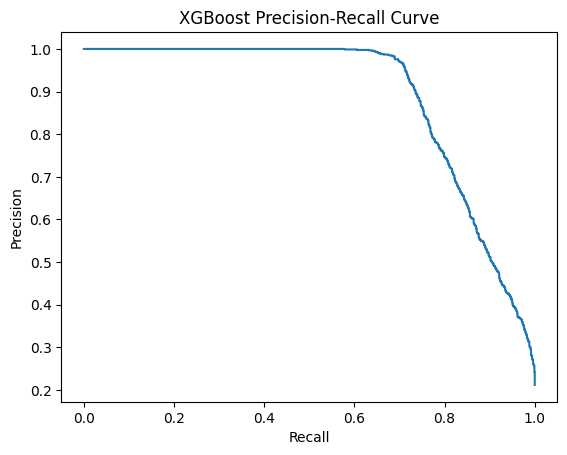

In [49]:
#Get the prob of class 1 from XGBoost
prob = xg_model.predict_proba(X_test)[:, 1]


#For each threshold calculate Precision and Recall
precisions, recalls, thresholds = precision_recall_curve(y_test, prob)


#Calculate F1 Score for each threshold
f1 = 2 * (precisions-recalls) / (precisions + recalls + 1e-9)
f1

#Get the threshold that produces the highest f1-score
best = np.argmax(f1[:-1])
best_thresholds = thresholds[best]

#Evaluate the XGBoost model using that threshold
evaluate_model("XGBoost", xg_model, X_test, y_test, best_thresholds)

# **13. Probability Calibration**

*   Sometimes a model's probability doent mean what it says
*   For example, 30% risk should truly mean a 30% chance.

*   We check this with a calibration plot.
*   We fix it if the probabilities are off.





In [50]:
"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probalities using a sigmoid curve
2. Isotonic Regression -> Adjust the probabilities using a sigmoid curve.
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature.
"""

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probalities using a sigmoid curve\n2. Isotonic Regression -> Adjust the probabilities using a sigmoid curve.\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature.\n'

In [51]:
#1.Calibrated XGBoost Model
from sklearn.calibration import CalibratedClassifierCV , calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(X_train, y_train)

CalibratedClassifierCV(cv=5,
                       estimator=Pipeline(steps=[('preprocessor',
                                                  ColumnTransformer(transformers=[('num',
                                                                                   Pipeline(steps=[('imputer',
                                                                                                    SimpleImputer(strategy='median')),
                                                                                                   ('scaler',
                                                                                                    StandardScaler())]),
                                                                                   ['person_age',
                                                                                    'person_income',
                                                                                    'person_emp_length',
                                                                                    'loan_amnt',
                                                                                    'loan_int_rate',
                                                                                    'loan_percent_income',
                                                                                    'cb_person_cred_hist_length']),
                                                                                  ('cat',
                                                                                   Pipeline(ste...
                                                                grow_policy=None,
                                                                importance_type=None,
                                                                interaction_constraints=None,
                                                                learning_rate=np.float64(0.09882547753898406),
                                                                max_bin=None,
                                                                max_cat_threshold=None,
                                                                max_cat_to_onehot=None,
                                                                max_delta_step=None,
                                                                max_depth=5,
                                                                max_leaves=None,
                                                                min_child_weight=4,
                                                                missing=nan,
                                                                monotone_constraints=None,
                                                                multi_strategy=None,
                                                                n_estimators=349,
                                                                n_jobs=None,
                                                                num_parallel_tree=None, ...))]))

In [52]:
#2. Get probabilities
uncalibrated = xg_model.predict_proba(X_test)[:, 1]
calibrated = calibrated_model.predict_proba(X_test)[:, 1]

In [53]:
#3. create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)


In [54]:
actual_cal, predicted_cal = calibration_curve(y_test, calibrated, n_bins=10)

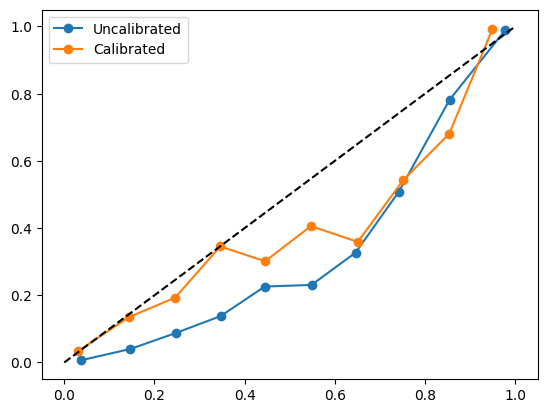

In [55]:
#4. Plot
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)
plt.plot([0, 1], [0, 1], "k--")
plt.legend()

# **14. SHAP Interpretation -- Global & Local**


*   SHAP helps us understand why the model makes a particular  decision.

*   SHAP tells which features pushed the predictions up or down and how much?


*   It is a way of explaining a "black box" model.



In [56]:
#1. Install SHAP if not exits
!pip install shap
import shap

In [57]:
#2. Get the Trained XGBoost classifier model out of the pipeline.
xgb_classifier = xg_model.named_steps['classifier']
xgb_classifier

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [58]:
#3. Transform X_test using the same preprocessing used for training.
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)


In [59]:
#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xg_model.named_steps['preprocessor'].get_feature_names_out()

In [60]:
#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [61]:
#6. Cretae SHAP explainer build for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)

In [62]:
#7. Calculate SHAP values fro every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[-7.7432315e-03, -7.5094008e-01, -1.2367868e-01, ...,
        -1.0665227e-02, -8.8718330e-04,  0.0000000e+00],
       [ 3.5132736e-02, -8.9686233e-01, -1.0950860e-01, ...,
        -1.1027072e-02, -6.7942322e-04,  0.0000000e+00],
       [ 3.2211039e-02, -1.6605960e-01, -8.8492788e-02, ...,
        -8.2157142e-03, -4.5424993e-03,  0.0000000e+00],
       ...,
       [ 3.1050751e-02, -9.8210394e-01, -1.2644650e-01, ...,
        -1.0403723e-02, -1.4258506e-03,  0.0000000e+00],
       [-5.3404653e-03, -8.5086465e-01,  5.8639098e-02, ...,
        -1.0982760e-02,  8.5223338e-04,  0.0000000e+00],
       [ 8.4826246e-02,  1.5625656e-01,  7.0657499e-02, ...,
        -9.0896273e-03, -1.5567085e-03,  0.0000000e+00]],
      shape=(6305, 26), dtype=float32)

Global explaination

*   This shows which features matter most overall.
*   It also shows if a features increases or decreases risk.



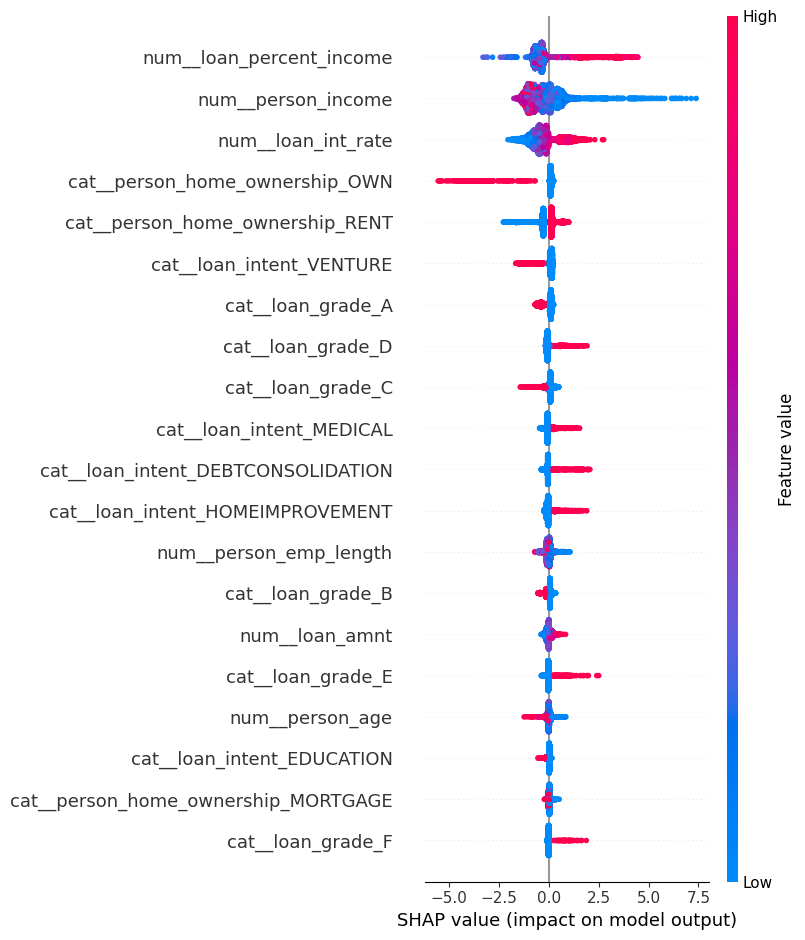

In [63]:
shap.summary_plot(shap_values, X_test_df)

Local Explaination

*   This shows why one specific applicat got their score.
*   It breaks the score down feature by feature.



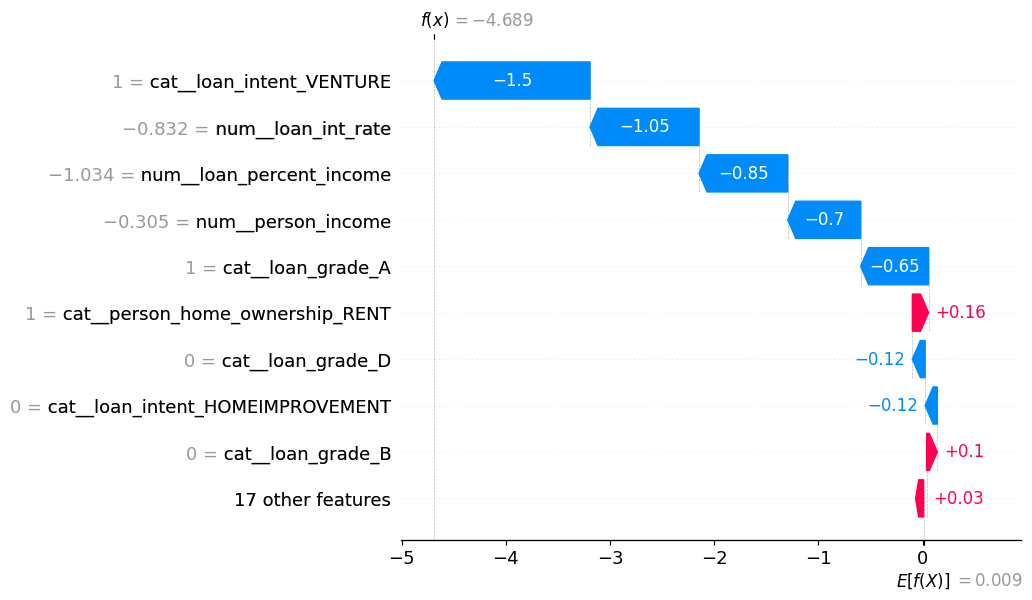

In [64]:
#1. Pick one row to explain, e.g the 5th applicabt in  the test set.
row_index = 5

#2. Draw a waterfall plot showing how waxh feature pushed the prediction up or down
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

# 15. Analyzing False Positive & False Negatives

*   The model will not be perfect.
*   False positives are safe people wrongly marked risky.

*   False negatives are risky people wrongly marked safe.
*   We Study these cases to understand where the model struggles.





In [65]:
#Get predictions from the best performing XGBoost model on  the test set
y_pred = random_search.predict(X_test)

In [66]:
#Create a dataframe to easily compare the actual and predicted values
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [67]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
8400,24,69996,RENT,5.0,VENTURE,A,7500,7.49,0.11,N,2,0,0
5698,23,150000,RENT,3.0,VENTURE,B,5000,10.65,0.03,N,2,0,0
15233,23,24000,OWN,5.0,EDUCATION,B,7000,11.86,0.29,N,4,0,0
28674,27,120000,MORTGAGE,11.0,PERSONAL,A,7000,6.76,0.06,N,7,0,0
26437,30,90000,MORTGAGE,7.0,DEBTCONSOLIDATION,A,4800,8.90,0.05,N,5,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
17341,24,75000,RENT,6.0,HOMEIMPROVEMENT,B,15000,11.71,0.20,N,4,0,0
13239,24,90000,MORTGAGE,0.0,DEBTCONSOLIDATION,C,8000,12.99,0.09,N,2,0,0
26469,33,103000,MORTGAGE,5.0,EDUCATION,A,24000,7.49,0.23,N,10,0,0
26680,32,110000,MORTGAGE,2.0,VENTURE,B,5600,10.74,0.05,N,7,0,0


In [68]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]


#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]


In [69]:
print(f"False Positives: {len(false_positive)}")
print(f"False Negatives: {len(false_negative)}")

False Positives: 239
False Negatives: 282


In [70]:
#False Negative > False Positive

# 16. Save the Final Model

*   Once we are happy with the model, we save it.
*   We also save the settings it needs, like the chosen threshold.

*   This saved file can now be used in a real application.





In [77]:
import joblib

joblib.dump(calibrated_model, "credit_risk_model.pkl")

['credit_risk_model.pkl']

In [78]:
from sklearn.metrics import precision_recall_curve
import numpy as np

#1. Get probabilities from the CALIBRATED model, not the xg_model
calibrated_proba = calibrated_model.predict_proba(X_test)[:, 1]

#2. Re-run the same threshold search, now on the correct probability scale
precisions, recalls, thresholds = precision_recall_curve(y_test, calibrated_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]

print("New threshold:", best_threshold)

New threshold: 0.7045898548083221


In [79]:
joblib.dump(best_thresholds, "best_threshold.pkl")

['best_threshold.pkl']